In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

DATA_PATH = Path("train.csv")

In [2]:
import os

# Fallback to California Housing dataset if train.csv is not present
alt_path = Path("sample_data/california_housing_train.csv")

if DATA_PATH.exists():
    df_raw = pd.read_csv(DATA_PATH)
    print("Loaded Ames Housing dataset (train.csv).")
elif alt_path.exists():
    df_raw = pd.read_csv(alt_path)
    print("train.csv not found. Loaded California Housing dataset instead.")
else:
    raise FileNotFoundError("Neither train.csv nor California Housing dataset could be found.")

df = df_raw.copy()

print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]:,} columns")
display(df.head())
df.info()

missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean().mul(100).round(2)
}).query("missing_count > 0").sort_values("missing_percent", ascending=False)

print(f"Columns containing missing values: {len(missing)}")
if len(missing) > 0:
    display(missing)
else:
    print("No missing values found in the dataset.")

train.csv not found. Loaded California Housing dataset instead.
Dataset shape: 17,000 rows × 9 columns


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17000 entries, 0 to 16999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           17000 non-null  float64
 1   latitude            17000 non-null  float64
 2   housing_median_age  17000 non-null  float64
 3   total_rooms         17000 non-null  float64
 4   total_bedrooms      17000 non-null  float64
 5   population          17000 non-null  float64
 6   households          17000 non-null  float64
 7   median_income       17000 non-null  float64
 8   median_house_value  17000 non-null  float64
dtypes: float64(9)
memory usage: 1.2 MB
Columns containing missing values: 0
No missing values found in the dataset.


In [3]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()

ordinal_orders = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"],
}
for col, order in ordinal_orders.items():
    if col in df.columns:
        df[col] = pd.Categorical(df[col], categories=order, ordered=True)

variable_summary = pd.DataFrame({
    "column": df.columns,
    "dtype": [str(df[c].dtype) for c in df.columns],
    "unique_values": [df[c].nunique(dropna=True) for c in df.columns],
    "example_values": [
        ", ".join(map(str, df[c].dropna().unique()[:5])) for c in df.columns
    ]
})
display(variable_summary)
print("Note: OverallQual is stored numerically but is an ordinal rating (1–10).")

,column,dtype,unique_values,example_values
0,longitude,float64,827,"-114.31, -114.47, -114.56, -114.57, -114.58"
1,latitude,float64,840,"34.19, 34.4, 33.69, 33.64, 33.57"
2,housing_median_age,float64,52,"15.0, 19.0, 17.0, 14.0, 20.0"
3,total_rooms,float64,5533,"5612.0, 7650.0, 720.0, 1501.0, 1454.0"
4,total_bedrooms,float64,1848,"1283.0, 1901.0, 174.0, 337.0, 326.0"
5,population,float64,3683,"1015.0, 1129.0, 333.0, 515.0, 624.0"
6,households,float64,1740,"472.0, 463.0, 117.0, 226.0, 262.0"
7,median_income,float64,11175,"1.4936, 1.82, 1.6509, 3.1917, 1.925"
8,median_house_value,float64,3694,"66900.0, 80100.0, 85700.0, 73400.0, 65500.0"


Note: OverallQual is stored numerically but is an ordinal rating (1–10).


In [4]:
display(df.describe().T)

# Pick available columns depending on whether Ames or California Housing is loaded
candidate_cols = [
    c for c in ["SalePrice", "GrLivArea", "LotArea", "median_house_value", "median_income", "housing_median_age"]
    if c in df.columns
]

stats_rows = []
for col in candidate_cols:
    s = df[col].dropna()
    mode_values = s.mode()
    stats_rows.append({
        "feature": col,
        "mean": s.mean(),
        "median": s.median(),
        "mode": mode_values.iloc[0] if not mode_values.empty else np.nan,
        "std_dev": s.std(),
        "variance": s.var(),
        "range": s.max() - s.min(),
        "Q1": s.quantile(0.25),
        "Q3": s.quantile(0.75),
        "IQR": s.quantile(0.75) - s.quantile(0.25),
        "skewness": s.skew(),
        "kurtosis": s.kurt(),
    })

descriptive = pd.DataFrame(stats_rows).set_index("feature")
display(descriptive)

for col in ["Neighborhood", "HouseStyle"]:
    if col in df.columns:
        print(f"\n{col} frequency counts:")
        display(df[col].value_counts(dropna=False).head(15).to_frame("count"))
        print("Mode:", df[col].mode().tolist())

,count,mean,std,min,25%,50%,75%,max
longitude,17000.0,-119.562108,2.005166,-124.3500,-121.790000,-118.4900,-118.000,-114.3100
latitude,17000.0,35.625225,2.137340,32.5400,33.930000,34.2500,37.720,41.9500
housing_median_age,17000.0,28.589353,12.586937,1.0000,18.000000,29.0000,37.000,52.0000
total_rooms,17000.0,2643.664412,2179.947071,2.0000,1462.000000,2127.0000,3151.250,37937.0000
total_bedrooms,17000.0,539.410824,421.499452,1.0000,297.000000,434.0000,648.250,6445.0000
population,17000.0,1429.573941,1147.852959,3.0000,790.000000,1167.0000,1721.000,35682.0000
households,17000.0,501.221941,384.520841,1.0000,282.000000,409.0000,605.250,6082.0000
median_income,17000.0,3.883578,1.908157,0.4999,2.566375,3.5446,4.767,15.0001
median_house_value,17000.0,207300.912353,115983.764387,14999.0000,119400.000000,180400.0000,265000.000,500001.0000


,mean,median,mode,std_dev,variance,range,Q1,Q3,IQR,skewness,kurtosis
feature,,,,,,,,,,,
median_house_value,207300.912353,180400.0000,500001.000,115983.764387,1.345223e+10,485002.0000,119400.000000,265000.000,145600.000000,0.973037,0.303998
median_income,3.883578,3.5446,3.125,1.908157,3.641061e+00,14.5002,2.566375,4.767,2.200625,1.626693,4.764145
housing_median_age,28.589353,29.0000,52.000,12.586937,1.584310e+02,51.0000,18.000000,37.000,19.000000,0.064894,-0.800826


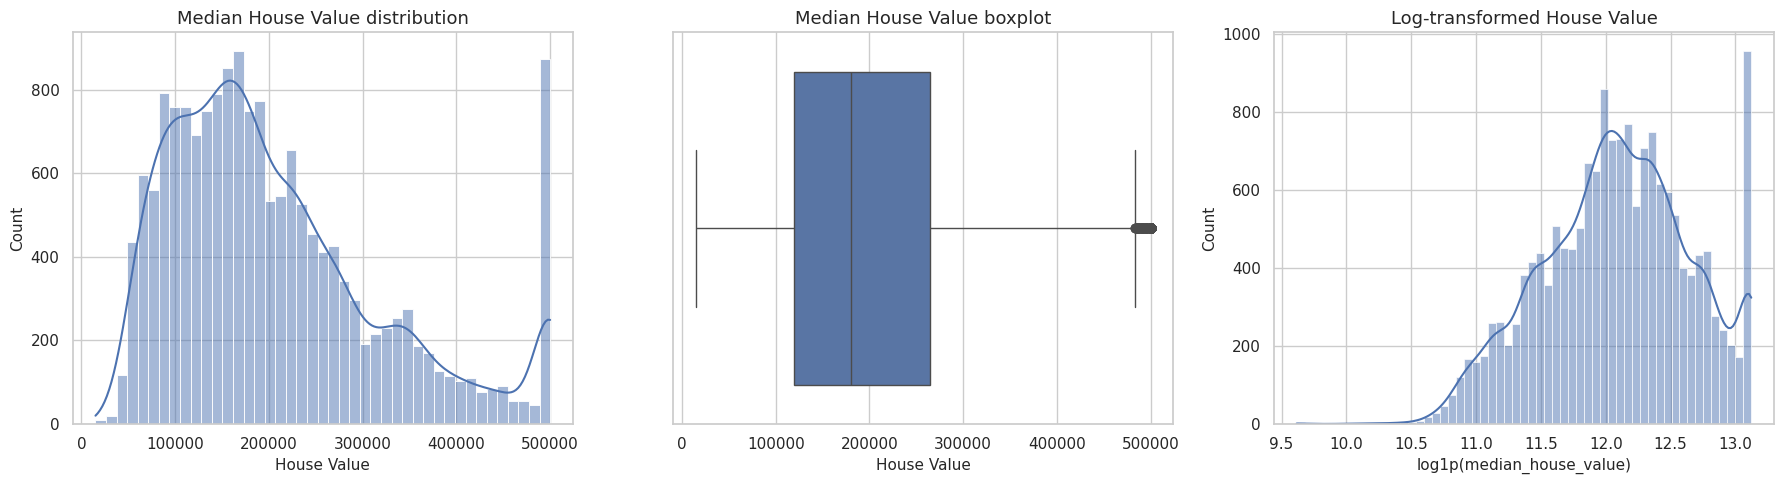

House Value skewness: 0.973
log1p(House Value) skewness: -0.179


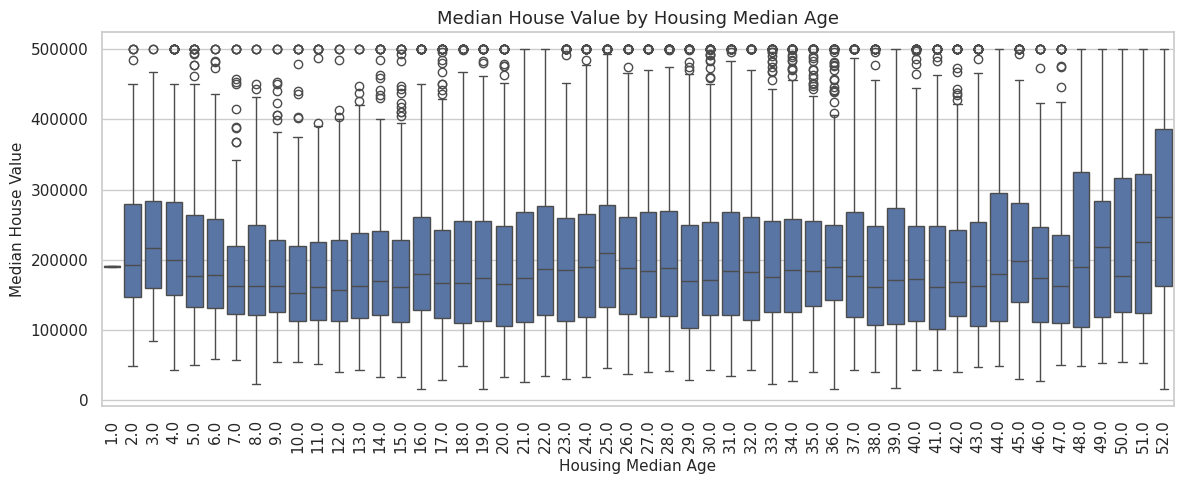

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Distribution of median_house_value
sns.histplot(df["median_house_value"].dropna(), kde=True, ax=axes[0])
axes[0].set(title="Median House Value distribution", xlabel="House Value")

sns.boxplot(x=df["median_house_value"], ax=axes[1])
axes[1].set(title="Median House Value boxplot", xlabel="House Value")

# Log transformation
log_price = np.log1p(df["median_house_value"].dropna())
sns.histplot(log_price, kde=True, ax=axes[2])
axes[2].set(title="Log-transformed House Value", xlabel="log1p(median_house_value)")

plt.tight_layout()
plt.show()

print("House Value skewness:", round(df["median_house_value"].skew(), 3))
print("log1p(House Value) skewness:", round(log_price.skew(), 3))

# Boxplot against Housing Median Age
plt.figure(figsize=(12, 5))
sns.boxplot(data=df, x="housing_median_age", y="median_house_value")
plt.title("Median House Value by Housing Median Age")
plt.xlabel("Housing Median Age")
plt.ylabel("Median House Value")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [6]:
target_col = "SalePrice" if "SalePrice" in df.columns else "median_house_value"

numeric_for_corr = df.select_dtypes(include=np.number)
cov_matrix = numeric_for_corr.cov()
corr_matrix = numeric_for_corr.corr(method="pearson")

target_corr = corr_matrix[target_col].drop(target_col).dropna()
top_corr = target_corr.reindex(target_corr.abs().sort_values(ascending=False).index)

print(f"Top 10 numerical features by absolute Pearson correlation with {target_col}:")
display(top_corr.head(10).rename("pearson_correlation").to_frame())

top3 = top_corr.head(3).index
comparison = pd.DataFrame({
    f"correlation_with_{target_col}": corr_matrix.loc[top3, target_col],
    f"covariance_with_{target_col}": cov_matrix.loc[top3, target_col]
})
display(comparison)

if {"GarageArea", "GarageCars"}.issubset(corr_matrix.columns):
    print("GarageArea–GarageCars correlation:", round(corr_matrix.loc["GarageArea", "GarageCars"], 3))

ordinal_numeric = [c for c in ["OverallQual", "OverallCond"] if c in df.columns]
if ordinal_numeric:
    display(df[ordinal_numeric + [target_col]].corr(method="spearman"))

Top 10 numerical features by absolute Pearson correlation with median_house_value:


,pearson_correlation
median_income,0.691871
latitude,-0.144917
total_rooms,0.130991
housing_median_age,0.106758
households,0.061031
total_bedrooms,0.045783
longitude,-0.044982
population,-0.027850


,correlation_with_median_house_value,covariance_with_median_house_value
median_income,0.691871,1.531215e+05
latitude,-0.144917,-3.592438e+04
total_rooms,0.130991,3.311968e+07


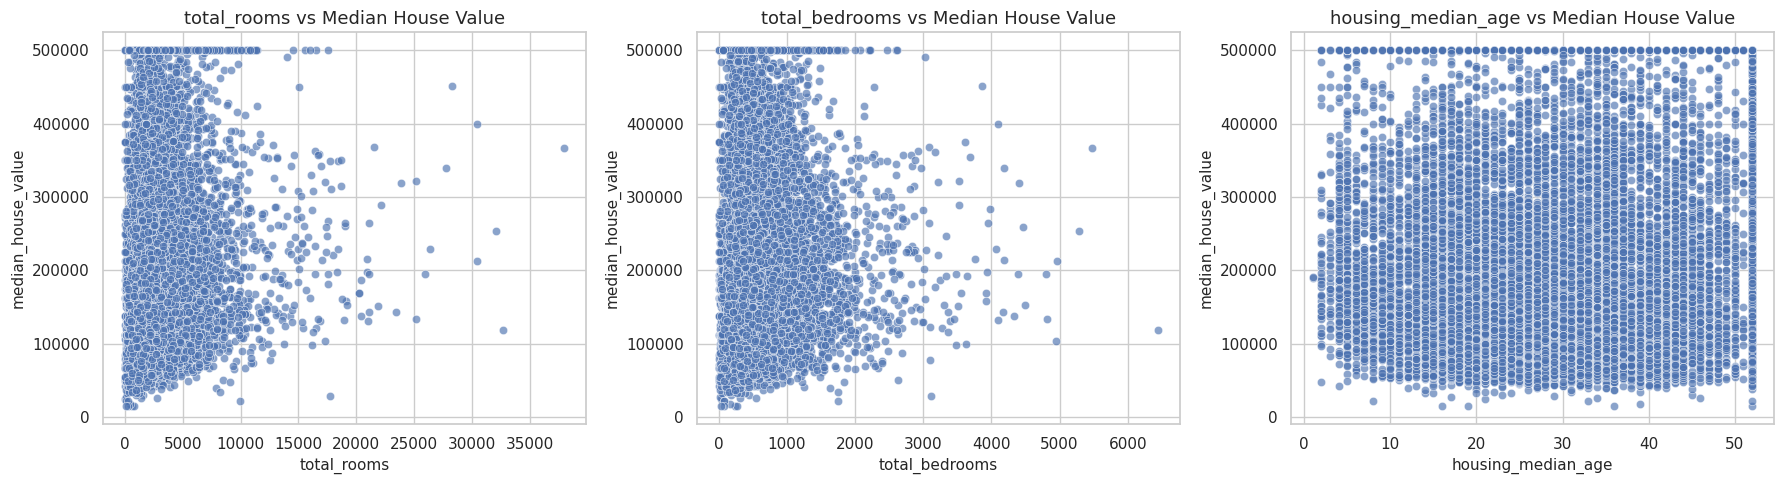

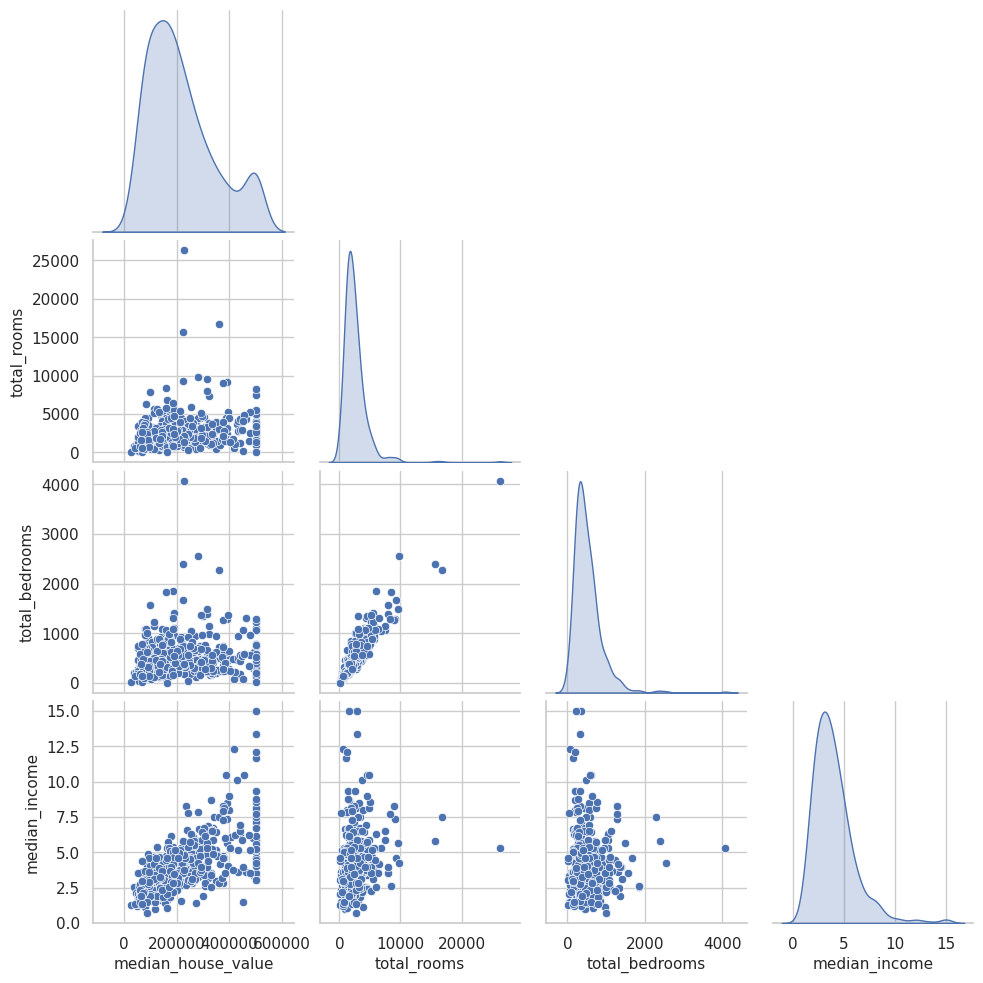

In [7]:
# Check which dataset features are available
if {"GrLivArea", "TotalBsmtSF", "YearBuilt", "SalePrice"}.issubset(df.columns):
    # Ames Housing
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, feature in zip(axes, ["GrLivArea", "TotalBsmtSF", "YearBuilt"]):
        sns.scatterplot(data=df, x=feature, y="SalePrice", alpha=0.65, ax=ax)
        ax.set_title(f"{feature} vs SalePrice")
    plt.tight_layout()
    plt.show()

    unusual = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 200000)]
    plt.figure(figsize=(9, 6))
    sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", alpha=0.45, label="Other homes")
    if not unusual.empty:
        sns.scatterplot(data=unusual, x="GrLivArea", y="SalePrice", color="red", s=90, label="Large area / low price")
        for idx, row in unusual.iterrows():
            plt.annotate(str(idx), (row["GrLivArea"], row["SalePrice"]))
    plt.title("Potentially unusual large homes")
    plt.legend()
    plt.show()

elif {"total_rooms", "total_bedrooms", "housing_median_age", "median_house_value"}.issubset(df.columns):
    # California Housing fallback
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, feature in zip(axes, ["total_rooms", "total_bedrooms", "housing_median_age"]):
        sns.scatterplot(data=df, x=feature, y="median_house_value", alpha=0.65, ax=ax)
        ax.set_title(f"{feature} vs Median House Value")
    plt.tight_layout()
    plt.show()

# Dynamic Pairplot
pair_features = [c for c in ["SalePrice", "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt",
                             "median_house_value", "total_rooms", "total_bedrooms", "median_income"] if c in df.columns]
pair_data = df[pair_features].dropna()
if len(pair_data) > 500:
    pair_data = pair_data.sample(500, random_state=42)

sns.pairplot(pair_data, diag_kind="kde", corner=True)
plt.show()

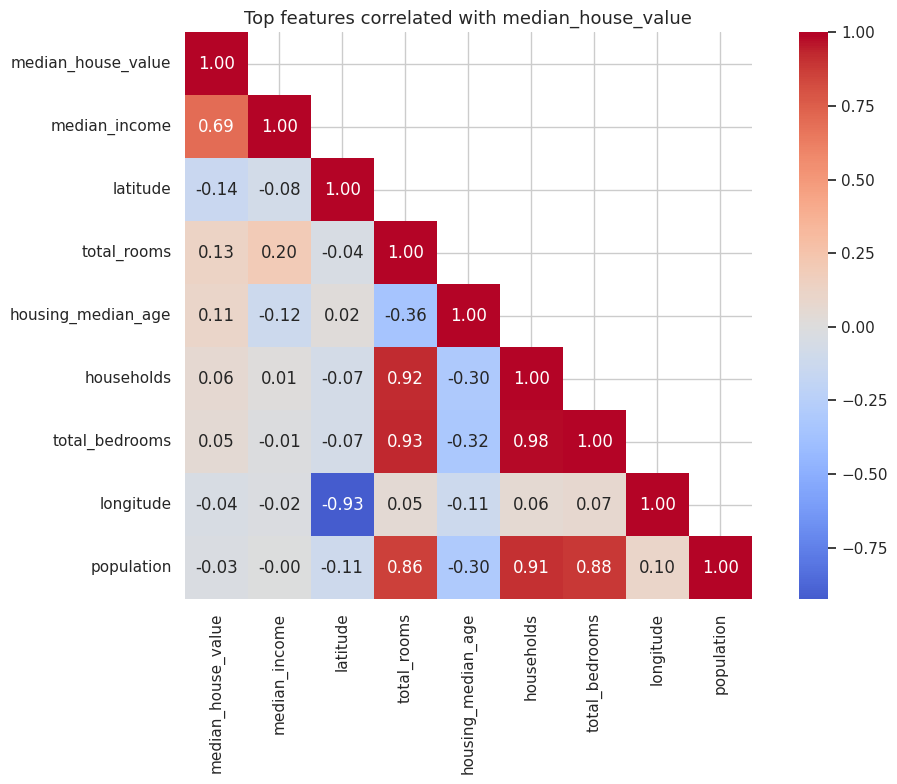

In [8]:
target_col = "SalePrice" if "SalePrice" in df.columns else "median_house_value"

# Keep only features that exist in df and avoid duplicating target_col
extra_cols = [c for c in top_corr.head(9).index.tolist() if c in df.columns and c != target_col]
top_features = [target_col] + extra_cols

corr_top = df[top_features].corr()
mask = np.triu(np.ones_like(corr_top, dtype=bool), k=1)

plt.figure(figsize=(11, 8))
sns.heatmap(
    corr_top,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
)
plt.title(f"Top features correlated with {target_col}")
plt.tight_layout()
plt.show()

,IQR_count,Z_score_count,overlap_count
feature,,,
total_rooms,1076,313,313
median_house_value,895,0,0


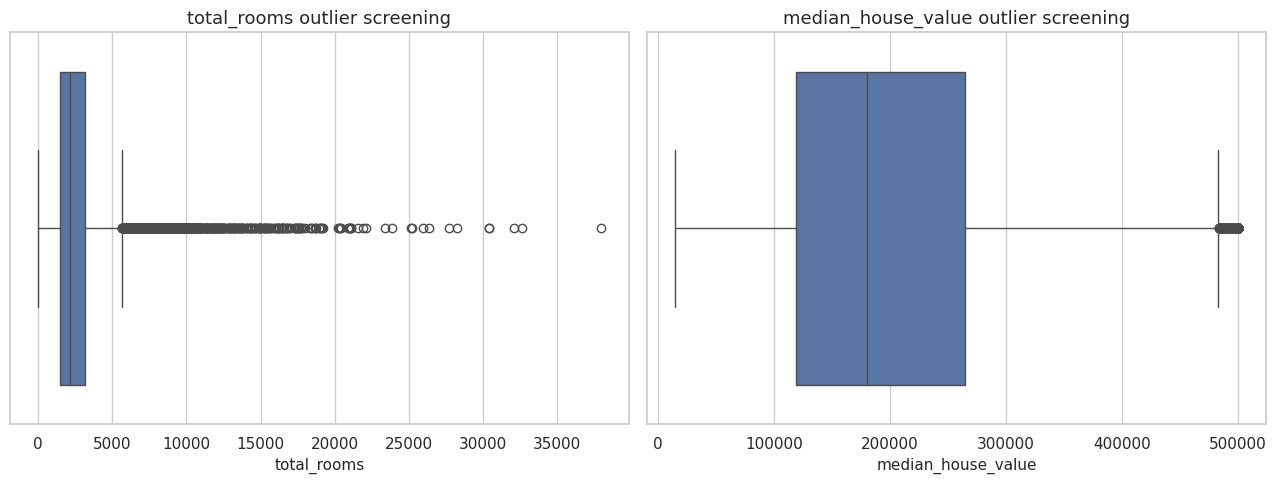

,total_rooms,median_house_value
2871,37937.0,366300.0
12772,32627.0,118800.0
2969,32054.0,253900.0
8881,30405.0,399200.0
1116,30401.0,212300.0
13299,28258.0,451100.0
3296,27700.0,339700.0
1836,26322.0,228900.0
8319,25957.0,195300.0
8959,25187.0,321300.0


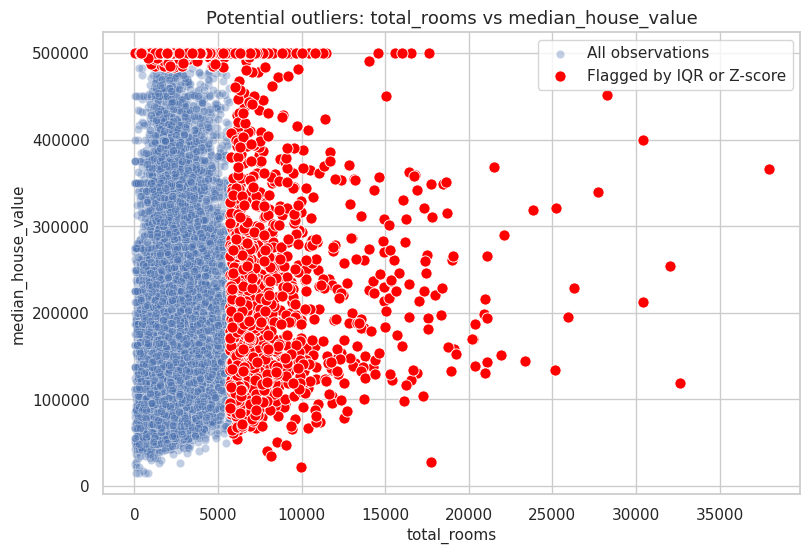

In [9]:
# Identify target and primary numerical feature dynamically
target_col = "SalePrice" if "SalePrice" in df.columns else "median_house_value"
feature_col = "GrLivArea" if "GrLivArea" in df.columns else "total_rooms"

def iqr_outliers(series):
    s = series.dropna()
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return series[(series < lower) | (series > upper)].dropna()

def zscore_outliers(series, threshold=3):
    s = series.dropna()
    if s.std(ddof=0) == 0:
        return series.iloc[0:0]
    z = (s - s.mean()) / s.std(ddof=0)
    return series.loc[z.index[abs(z) > threshold]]

outlier_summary = []
flagged_indices = {}

for col in [feature_col, target_col]:
    iqr_flag = iqr_outliers(df[col])
    z_flag = zscore_outliers(df[col])
    flagged_indices[col] = set(iqr_flag.index) | set(z_flag.index)
    outlier_summary.append({
        "feature": col,
        "IQR_count": len(iqr_flag),
        "Z_score_count": len(z_flag),
        "overlap_count": len(set(iqr_flag.index) & set(z_flag.index))
    })

display(pd.DataFrame(outlier_summary).set_index("feature"))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(x=df[feature_col], ax=axes[0])
axes[0].set_title(f"{feature_col} outlier screening")
sns.boxplot(x=df[target_col], ax=axes[1])
axes[1].set_title(f"{target_col} outlier screening")
plt.tight_layout()
plt.show()

combined_flag = set.union(*flagged_indices.values())
df_flagged = df.loc[sorted(combined_flag)].copy()
display(df_flagged[[feature_col, target_col]].sort_values(feature_col, ascending=False).head(20))

plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x=feature_col, y=target_col, alpha=.35, label="All observations")
if combined_flag:
    sns.scatterplot(
        data=df.loc[sorted(combined_flag)],
        x=feature_col,
        y=target_col,
        color="red",
        s=65,
        label="Flagged by IQR or Z-score"
    )
plt.title(f"Potential outliers: {feature_col} vs {target_col}")
plt.legend()
plt.show()


In [10]:
df_clean = df_raw.copy()

duplicate_count = int(df_clean.duplicated().sum())
print("Exact duplicate rows:", duplicate_count)
if duplicate_count:
    df_clean = df_clean.drop_duplicates().copy()
print("Shape after duplicate check:", df_clean.shape)

# Standardize whitespace in object columns without changing category spelling/case.
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()

# Missing categorical values that represent an absent feature.
absent_means_none = [
    "PoolQC", "Alley", "Fence", "FireplaceQu", "GarageType",
    "GarageFinish", "GarageQual", "GarageCond", "BsmtQual",
    "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "MasVnrType"
]
for col in absent_means_none:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna("None")

# Numeric absence indicators: no masonry veneer / no garage / no basement.
for col in ["MasVnrArea", "GarageYrBlt"]:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna(0)

# LotFrontage is plausibly related to neighborhood; use neighborhood median,
# then global median as a fallback for neighborhoods with no observed values.
if "LotFrontage" in df_clean.columns:
    if "Neighborhood" in df_clean.columns:
        df_clean["LotFrontage"] = df_clean["LotFrontage"].fillna(
            df_clean.groupby("Neighborhood")["LotFrontage"].transform("median")
        )
    df_clean["LotFrontage"] = df_clean["LotFrontage"].fillna(df_clean["LotFrontage"].median())

# Remaining object columns: explicit Unknown label. Remaining numeric columns:
# median imputation is used only to produce a complete EDA working table.
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].fillna("Unknown")
for col in df_clean.select_dtypes(include=np.number).columns:
    if df_clean[col].isna().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

remaining_missing = df_clean.isna().sum()
print("Remaining missing cells:", int(remaining_missing.sum()))
display(remaining_missing[remaining_missing > 0].to_frame("missing_count"))

# Basic impossible-value checks
if {"YearBuilt", "YrSold"}.issubset(df_clean.columns):
    impossible_years = df_clean[df_clean["YearBuilt"] > df_clean["YrSold"]]
    print("Rows where YearBuilt > YrSold:", len(impossible_years))
area_cols = [c for c in ["LotArea", "GrLivArea", "TotalBsmtSF", "GarageArea"] if c in df_clean.columns]
for col in area_cols:
    print(f"Negative {col} values:", int((df_clean[col] < 0).sum()))

print("Cleaned data shape:", df_clean.shape)

Exact duplicate rows: 0
Shape after duplicate check: (17000, 9)
Remaining missing cells: 0


,missing_count


Cleaned data shape: (17000, 9)


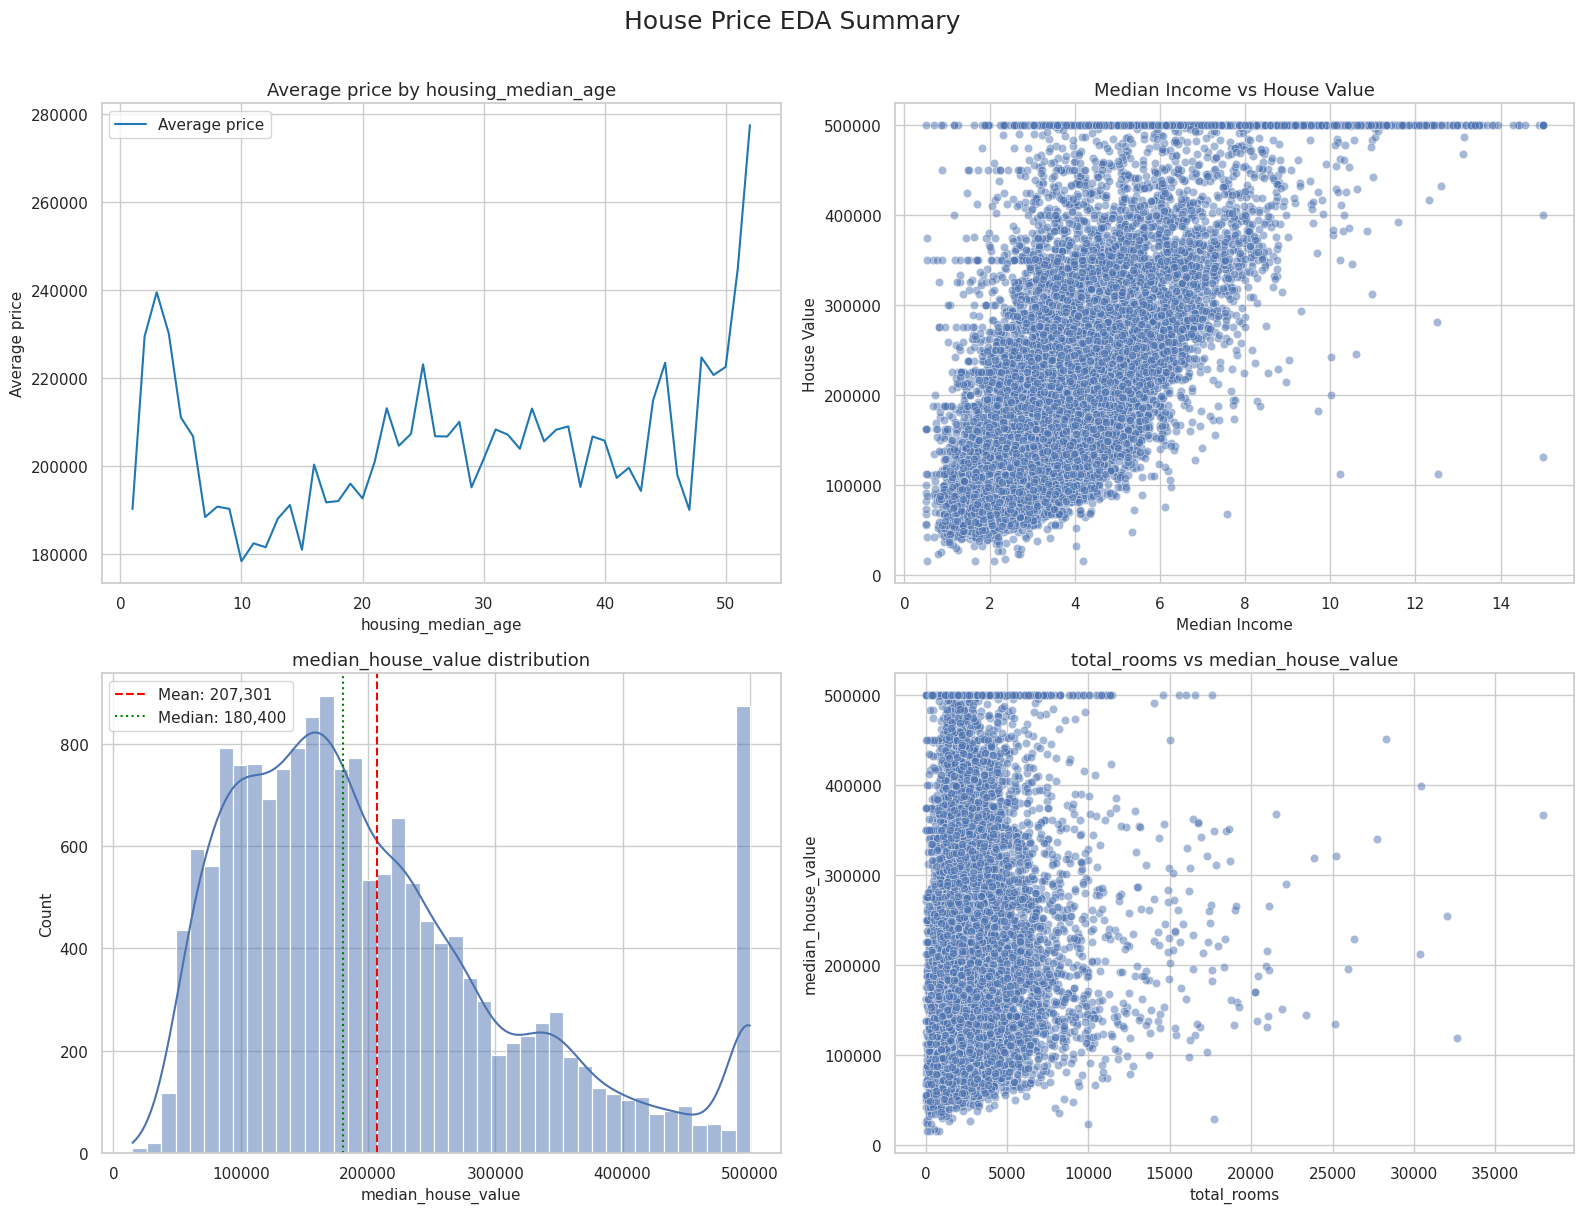

Dashboard saved as eda_dashboard.png


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Determine dataset columns dynamically
target_col = "SalePrice" if "SalePrice" in df_clean.columns else "median_house_value"
group_col = "YearBuilt" if "YearBuilt" in df_clean.columns else "housing_median_age"
cat_col = "Neighborhood" if "Neighborhood" in df_clean.columns else None
feature_col = "GrLivArea" if "GrLivArea" in df_clean.columns else "total_rooms"
hue_col = "OverallQual" if "OverallQual" in df_clean.columns else None

# Panel 1: Average price by year/age
year_price = df_clean.groupby(group_col, as_index=False)[target_col].mean()
axes[0, 0].plot(year_price[group_col], year_price[target_col], label="Average price", color="tab:blue")
axes[0, 0].set(title=f"Average price by {group_col}", xlabel=group_col, ylabel="Average price")
axes[0, 0].legend()

# Panel 2: Top categories or Income vs Value
if cat_col:
    cat_mean = df_clean.groupby(cat_col)[target_col].mean().sort_values(ascending=False).head(10).sort_values()
    cat_mean.plot(kind="barh", ax=axes[0, 1])
    axes[0, 1].set(title=f"Top 10 {cat_col}s by mean price", xlabel="Mean price", ylabel=cat_col)
else:
    sns.scatterplot(data=df_clean, x="median_income", y=target_col, alpha=0.5, ax=axes[0, 1])
    axes[0, 1].set(title="Median Income vs House Value", xlabel="Median Income", ylabel="House Value")

# Panel 3: Target distribution with mean and median
sns.histplot(df_clean[target_col], kde=True, ax=axes[1, 0])
mean_price = df_clean[target_col].mean()
median_price = df_clean[target_col].median()
axes[1, 0].axvline(mean_price, color="red", linestyle="--", label=f"Mean: {mean_price:,.0f}")
axes[1, 0].axvline(median_price, color="green", linestyle=":", label=f"Median: {median_price:,.0f}")
axes[1, 0].set(title=f"{target_col} distribution", xlabel=target_col)
axes[1, 0].legend()

# Panel 4: Living area / total rooms vs target price
if hue_col:
    sns.scatterplot(data=df_clean, x=feature_col, y=target_col, hue=hue_col, palette="viridis", alpha=0.7, ax=axes[1, 1])
    axes[1, 1].legend(title=hue_col, bbox_to_anchor=(1.02, 1), loc="upper left")
else:
    sns.scatterplot(data=df_clean, x=feature_col, y=target_col, alpha=0.5, ax=axes[1, 1])
axes[1, 1].set(title=f"{feature_col} vs {target_col}", xlabel=feature_col, ylabel=target_col)

fig.suptitle("House Price EDA Summary", fontsize=18, y=1.01)
plt.tight_layout()
fig.savefig("eda_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()

print("Dashboard saved as eda_dashboard.png")

In [12]:
target_col = "SalePrice" if "SalePrice" in df_clean.columns else "median_house_value"
group_col = "Neighborhood" if "Neighborhood" in df_clean.columns else None

print("EDA conclusion prompts")
print(f"1. {target_col} skewness (raw):", round(df_clean[target_col].skew(), 3))
print(f"2. {target_col} mean:", round(df_clean[target_col].mean(), 2))
print(f"3. {target_col} median:", round(df_clean[target_col].median(), 2))

if "top_corr" in globals():
    print("4. Strongest numeric correlations:")
    display(top_corr.head(5).to_frame("Pearson correlation"))

if group_col:
    print(f"5. Highest median-price {group_col}s:")
    display(df_clean.groupby(group_col)[target_col].median().sort_values(ascending=False).head(5).to_frame(f"median {target_col}"))

    print(f"6. Highest mean-price {group_col}s:")
    display(df_clean.groupby(group_col)[target_col].mean().sort_values(ascending=False).head(5).to_frame(f"mean {target_col}"))

EDA conclusion prompts
1. median_house_value skewness (raw): 0.973
2. median_house_value mean: 207300.91
3. median_house_value median: 180400.0
4. Strongest numeric correlations:


,Pearson correlation
median_income,0.691871
latitude,-0.144917
total_rooms,0.130991
housing_median_age,0.106758
households,0.061031
